# O(3) flow — Section 6.2

Learn an invariant encoder, a discrete-time quotient map, and an orbit decoder jointly with EMLP/Objax. Compare the learned and analytical dynamics using CMGDB Morse graphs and reconstructed original-space Conley indices.

Run the cells in order. The training cell loads the saved fit by default; set `retrain=True` to train with the displayed configuration.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
from quotient_fitting import fit_quotient
from example_plots import paper_reference, show_analytical
from quotient_notebook import show_quotient_fit
from quotient_domain_notebook import quotient_domain_study, show_domain_comparison
ROOT, EXAMPLES, DATA = workspace()
from o3_joint_comparison import show_joint_comparison

from o3_reconstruction import show_reconstruction


Bernardo's code: 21acca6; numerical input checksums verified.


## System and analytical quotient

The state is (a, v) in [−3/2, 3/2] × B³₃/₂. The ODE is

$$
\dot a=a(1-a^2),\qquad \dot v=(1-2a^2-\|v\|^2)v.
$$

O(3) acts by rotating v. The analytical quotient encoder and time-log(3) map are

$$
q(a,v)=(a,r),\qquad r=\|v\|,
$$

$$
\bar F(a,r)=\left(\frac{3a}{\sqrt{d}},\frac{3r}{\sqrt{d(d+8r^2)}}\right),\qquad d=1+8a^2.
$$

The full-space index graph below is the manuscript’s analytical reconstruction from the orbit fibers.

In [2]:
reference = paper_reference(ROOT, EXAMPLES, DATA, "o3")
show_analytical(reference, "o3")

Matplotlib is building the font cache; this may take a moment.


## Joint encoder, quotient map and orbit decoder

Let x = (a,v), r = ‖v‖ and q₀(x) = (a,r). Three official EMLP/Objax networks learn positive gain corrections:

$$
E_\theta(x)=q_0(x)\odot\exp\!\left(0.25\tanh N_\theta(S^{-1}x)\right),
$$

$$
f_\psi(q)=q\odot\exp\!\left(3\tanh(N_\psi(q)/3)\right),\qquad
\widehat q_\phi(q)=q\odot\exp\!\left(0.5\tanh N_\phi(q)\right).
$$

Here ⊙ and exp act componentwise. The orbit decoder is Dφ(q) = (q̂φ,₁(q), q̂φ,₂(q), 0, 0). The encoder network has one scalar plus one O(3) vector input and two invariant scalar outputs. The other networks use scalar representations. S contains a training-data RMS scalar scale and a shared RMS vector-component scale; latent coordinates are not additionally standardized.

**The known map (a,‖v‖) is explicitly used in the encoder.** The network learns corrections, not the quotient geometry from scratch. Positive gains preserve the signs of a and the zero-radius boundary. Preservation of the entire finite encoder image is checked numerically below.

For pairs x⁺ = Fτ(x), jointly minimize orbit reconstruction, orbit prediction, and latent consistency:

$$
L_{\rm rec}=\mathbb E\,d_G(D(E(x)),x)^2,\quad
L_{\rm pred}=\mathbb E\,d_G(D(f(E(x))),x^+)^2,\quad
L_{\rm con}=\mathbb E\,\|f(E(x))-E(x^+)\|^2.
$$

For O(3), orbit distance squared is (â−a)²+(r̂−‖v‖)². State errors are divided by 1.5 before squaring. The objective also includes cycle-consistency (weight 0.1) and latent-spread (weight 0.01) regularization. Reconstruction uses both members of each pair.

Use 16,384 random training starts, 4,096 validation starts, 4,096 test starts, and 20,000 joint updates. The scalar and radius are uniform on their intervals and directions are uniform on S². No special points are inserted. Select the checkpoint by validation loss, before CMGDB.

**Training time τ = log(3); CMGDB uses one learned step of the same duration.** The plot refreshes every 200 updates. `retrain=True` starts a fresh fit; otherwise the saved checkpoint is loaded.


In [3]:
import numpy as np
fit = fit_quotient("o3", training="joint", parameterization="gain", seed=0,
                   train_starts=16384, validation_starts=4096, test_starts=4096,
                   joint_steps=20000, training_boundary_fraction=0.0,
                   validation_boundary_fraction=0.0, time_step=float(np.log(3)),
                   cmgdb_iterations=1, retrain=False, live=True)

Loaded raw-state o3 quotient fit (seed 0).


In [4]:
show_quotient_fit(fit)

<Figure size 1200x320 with 4 Axes>

Held-out orbit RMS / state scale,Reconstruction,One step,Ten steps
Raw states,0.10%,0.38%,0.22%


## CMGDB comparison

Compare the analytical, native learned, and aggregated quotient graphs. Aggregation includes connecting cells and recomputes indices with CMGDB; a fixed-model grid-placement check tests sensitivity to the grid. Cell images are sampled, so these are numerical results rather than certified enclosures.


Grid per axis,Analytical time 1.099,Learned rectangle,Learned encoder image
32,4,8,8
64,4,6,6
128,5,6,6
256,4,6,6


Labels and colors identify the four aggregates. The middle row shows the corresponding computed quotient indices on the rectangular grids; these indices are not transferred to the restricted Atlas domain. The bottom row reconstructs the original-space indices using degree +1 sphere fibers (the specified learned lift in the right column). Solid cells are native Morse sets, colored by their aggregate. At **64 × 64**, pale basin colors are restricted to the one-step image cells; pale green marks O-to-C paths. Each panel uses its own quotient coordinates. White is uncolored, not necessarily outside the basin. These are finite-graph labels, not certified RoA. Index computations use the finer grids reported below.

Grid,Native learned,Aggregated,Analytical graph + indices
64,6,4,Match
128,6,4,Match
256,6,4,Match


Grid,Aligned grid: native nodes,Half-cell shift: native nodes,All aggregated indices match
128,4,7,Yes
256,4,7,Yes



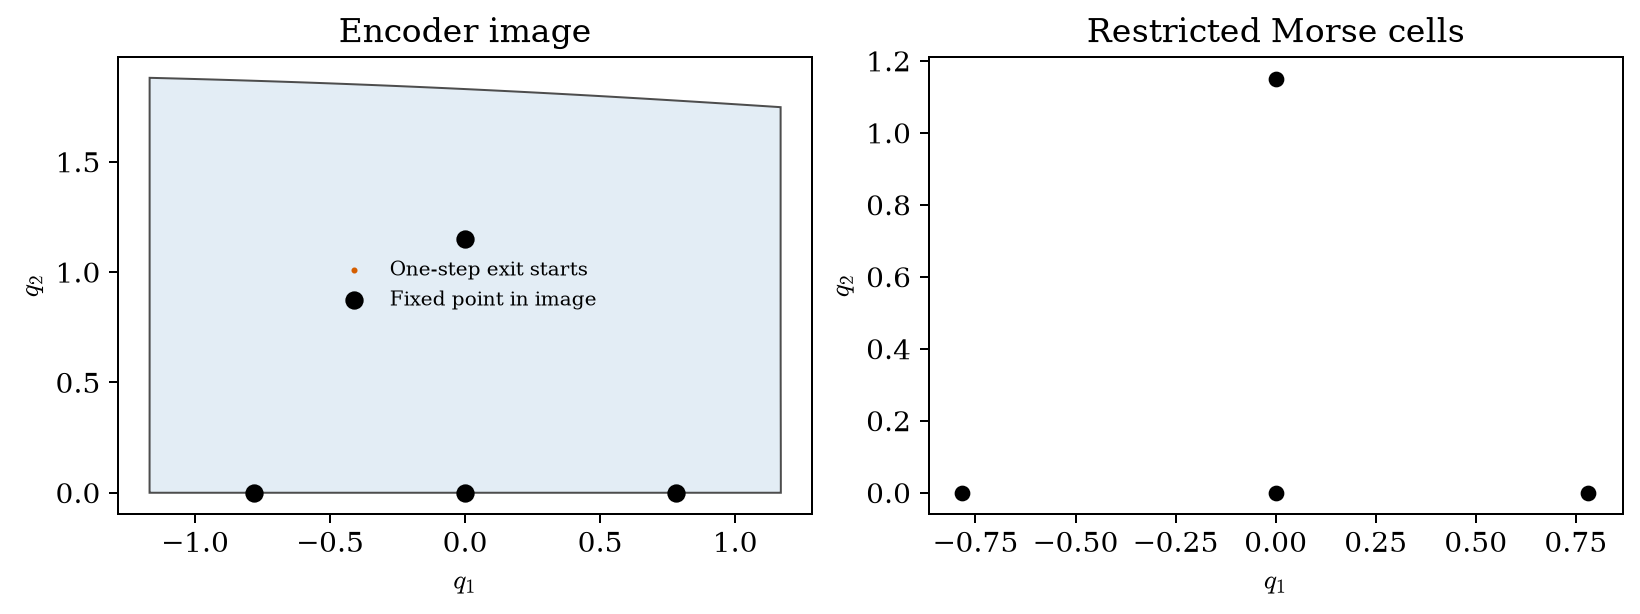

### Original-space reconstruction

The nonzero-radius fibers are $S^2$; they collapse on $P=\{r=0\}$. We use the direction-preserving lift (fiber degree $+1$). For quotient local pairs $(B,L)$,

$$H_k(N_X,L_X) \cong H_k(B,L)\oplus H_{k-2}(B,L\cup(B\cap P)).$$

Arb interval bounds verify local expansion/contraction and unique fixed-point brackets for this saved map. These give a local isolating continuation to the positive normal forms, whose index maps are identities. CMGDB computes the relative-chain indices over $\mathbb F_5$; entries below run from degree 0 to 4.


Set,Quotient classes,Additional original-space classes,Original-space classes
Origin,None,H₄,H₄
Saddle sphere,H₁,H₃,"H₁, H₃"
Each sink,H₀,None,H₀


The local indices of the specified learned lift are supported by uniform interval bounds. The global graph and basin labels use sampled CMGDB images; transfer to physical coordinates requires an encoder conjugacy, and transfer to the true ODE needs a model-error/continuation argument. The quotient graph alone does not determine the fiber degree. [Bounds and local continuation argument](../build/o3-certification/local-index-argument.md).

**Approximate dynamics agreement:** at physical quotient fixed points, the largest one-step defect $\|f(E(x_*))-E(x_*)\|$ is **0.0039923** (sample interval 1.0986). The learned lifts’ verified local indices match the analytical indices. Transfer to the physical ODE requires suitable encoder coordinates and a neighborhood-wide error bound small enough to preserve isolation along a continuation; the sampled residual does not establish these conditions. [Details](../build/conjugacy-check/claim-scope.md).

In [5]:
study = quotient_domain_study(fit, levels=(5, 6, 7, 8))
show_joint_comparison(reference, fit, study)
reconstruction = show_reconstruction(fit)
